# 07 — Hybrid EfficientNetB3 + MobileNetV2
**Retinopathy Detection System**

Two-branch feature-fusion model:
- EfficientNetB3 branch: 300×300 RGB input in 0–255 range (Keras EfficientNet includes rescaling).
- MobileNetV2 branch: same augmented image resized to 224×224, then rescaled to -1..1.
- Global-average-pooled features are concatenated and classified into five classes.

**85% accuracy is a target, not a guarantee.** A hybrid can perform worse than its individual branches. We will use the exact saved train/validation IDs from Notebook 05, report the measured results honestly, and not change the validation split to inflate the score. This model is computationally heavier; use batch size 8 on CPU.

## 1. Imports and reproducibility

In [1]:
import os, sys, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
TensorFlow: 2.16.1
GPU: []


## 2. Project paths and dataset

In [2]:
PROJECT_ROOT = Path(r"S:\ISP")
DATA_ROOT = PROJECT_ROOT / "data"
MODEL_DIR = DATA_ROOT / "processed" / "models"
RESULT_DIR = DATA_ROOT / "processed" / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_SPLIT = RESULT_DIR / "efficientnetb3_train_split.csv"
VAL_SPLIT = RESULT_DIR / "efficientnetb3_validation_split.csv"
for p in [TRAIN_SPLIT, VAL_SPLIT]:
    if not p.exists():
        raise FileNotFoundError(f"Required split file not found: {p}")

csvs = [p for p in (DATA_ROOT / "raw").rglob("train.csv")
        if "aptos" in str(p).lower()]
if not csvs:
    raise FileNotFoundError("APTOS train.csv not found under S:/ISP/data/raw.")
DATASET_DIR = csvs[0].parent
IMAGE_DIR = DATASET_DIR / "train_images"
if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image folder not found: {IMAGE_DIR}")

print("Dataset:", DATASET_DIR)
print("Image folder:", IMAGE_DIR)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

Dataset: S:\ISP\data\raw\aptos\aptos2019-blindness-detection
Image folder: S:\ISP\data\raw\aptos\aptos2019-blindness-detection\train_images
Models: S:\ISP\data\processed\models
Results: S:\ISP\data\processed\results


## 3. Load and verify the original split

In [3]:
train_df = pd.read_csv(TRAIN_SPLIT)
val_df = pd.read_csv(VAL_SPLIT)
for frame in (train_df, val_df):
    frame["id_code"] = frame["id_code"].astype(str)
    frame["diagnosis"] = pd.to_numeric(frame["diagnosis"]).astype(int)
    frame["image_path"] = frame["id_code"].apply(lambda x: str(IMAGE_DIR / f"{x}.png"))

missing_train = train_df.loc[~train_df.image_path.apply(os.path.isfile), "image_path"]
missing_val = val_df.loc[~val_df.image_path.apply(os.path.isfile), "image_path"]
if len(missing_train) or len(missing_val):
    raise FileNotFoundError(f"Missing images: train={len(missing_train)}, val={len(missing_val)}")
if set(train_df.id_code) & set(val_df.id_code):
    raise ValueError("Train and validation IDs overlap.")
if not train_df.diagnosis.between(0, 4).all() or not val_df.diagnosis.between(0, 4).all():
    raise ValueError("Expected class labels 0–4.")
print("Training:", len(train_df), "| Validation:", len(val_df))
display(train_df.diagnosis.value_counts().sort_index().to_frame("train_count"))
display(val_df.diagnosis.value_counts().sort_index().to_frame("validation_count"))

Training: 2929 | Validation: 733


,train_count
diagnosis,
0,1444
1,296
2,799
3,154
4,236


,validation_count
diagnosis,
0,361
1,74
2,200
3,39
4,59


## 4. Create the input pipeline

In [4]:
IMG_SIZE = 300
BATCH_SIZE = 8  # If memory errors occur, change to 4.
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE

def load_hybrid_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # raw 0–255 for branch-specific preprocessing
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame.image_path.values, frame.diagnosis.values.astype(np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_hybrid_image, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, yb.shape)
print("Pixel range:", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))

Batch: (8, 300, 300, 3) (8,)
Pixel range: 0.0 to 255.0


## 5. Preview images

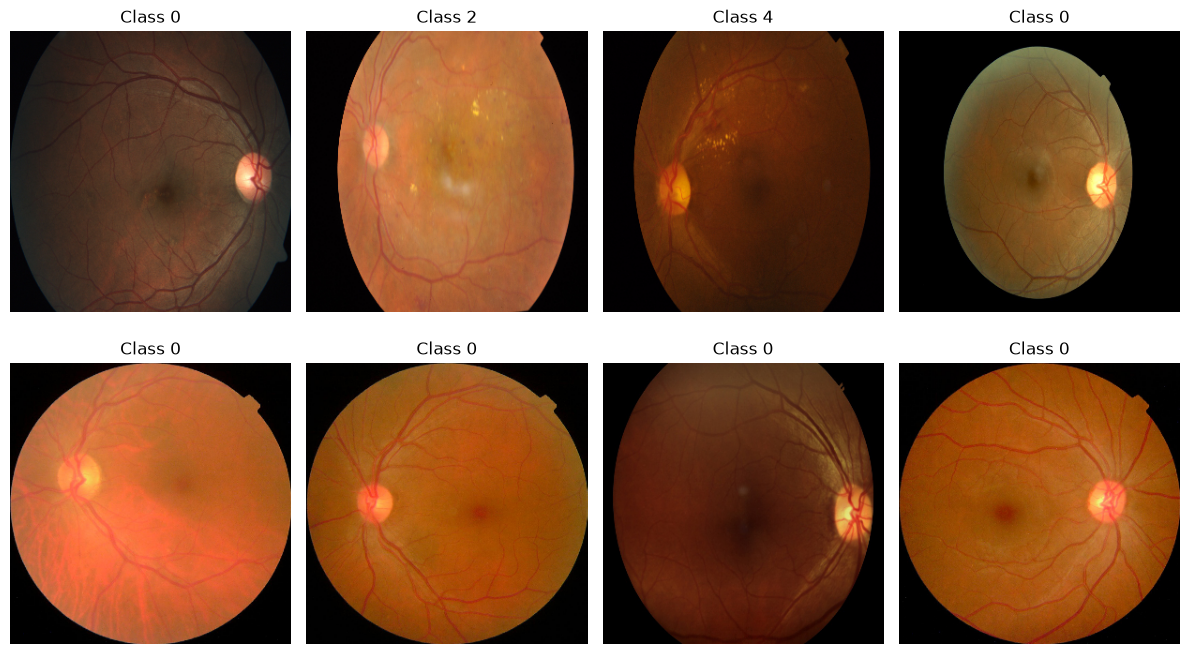

In [5]:
plt.figure(figsize=(12, 7))
for x, y in train_ds.take(1):
    for i in range(min(8, len(x))):
        plt.subplot(2, 4, i+1)
        plt.imshow(tf.cast(tf.clip_by_value(x[i], 0, 255), tf.uint8).numpy())
        plt.title(f"Class {int(y[i])}"); plt.axis("off")
plt.tight_layout(); plt.show()

## 6. Calculate class weights

In [6]:
class_ids = np.arange(NUM_CLASSES)
weights = compute_class_weight("balanced", classes=class_ids,
                               y=train_df.diagnosis.values)
class_weights = {int(k): float(v) for k, v in zip(class_ids, weights)}
print("Class weights:", class_weights)

Class weights: {0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


## 7. Build the hybrid architecture

In [7]:
# The same augmentation is shared by both branches.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.035),
    tf.keras.layers.RandomZoom(0.05)
], name="shared_augmentation")

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3), name="retinal_image")
augmented = augmentation(inputs)

# Branch 1: EfficientNetB3 expects RGB pixels 0–255; it contains internal rescaling.
efficientnet_base = tf.keras.applications.EfficientNetB3(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3))
efficientnet_base.trainable = False
eff = efficientnet_base(augmented, training=False)
eff = tf.keras.layers.GlobalAveragePooling2D(name="eff_global_pool")(eff)

# Branch 2: MobileNetV2 expects 224×224 pixels scaled to -1..1.
mob = tf.keras.layers.Resizing(224, 224, name="mobile_resize")(augmented)
mob = tf.keras.layers.Rescaling(1.0/127.5, offset=-1.0,
                                name="mobile_preprocess")(mob)
mobilenet_base = tf.keras.applications.MobileNetV2(
    include_top=False, weights="imagenet",
    input_shape=(224, 224, 3))
mobilenet_base.trainable = False
mob = mobilenet_base(mob, training=False)
mob = tf.keras.layers.GlobalAveragePooling2D(name="mobile_global_pool")(mob)

fused = tf.keras.layers.Concatenate(name="feature_fusion")([eff, mob])
x = tf.keras.layers.BatchNormalization()(fused)
x = tf.keras.layers.Dropout(0.45)(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax",
                                name="grade_output")(x)

model = tf.keras.Model(inputs, outputs, name="hybrid_efficientnetb3_mobilenetv2")
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "hybrid_efficientnetb3_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ retinal_image       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_augmentation │ (None, 300, 300,  │          0 │ retinal_image[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobile_resize       │ (None, 224, 224,  │          0 │ shared_augmentat… │
│ (Resizing)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobile_preprocess   │ (None, 224, 224,  │          0 │ mobile_resize[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb3      │ (None, 10, 10,    │ 10,783,535 │ shared_augmentat… │
│ (Functional)        │ 1536)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ mobile_preproces… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ eff_global_pool     │ (None, 1536)      │          0 │ efficientnetb3[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobile_global_pool  │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 2816)      │          0 │ eff_global_pool[… │
│ (Concatenate)       │                   │            │ mobile_global_po… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2816)      │     11,264 │ feature_fusion[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2816)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    721,152 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ grade_output        │ (None, 5)         │      1,285 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,776,244 (52.55 MB)

 Trainable params: 728,581 (2.78 MB)

 Non-trainable params: 13,047,663 (49.77 MB)

## 8. Train the fusion head (backbones frozen)

In [8]:
HEAD_EPOCHS = 6
HEAD_CHECKPOINT = MODEL_DIR / "hybrid_stage1_best.keras"
callbacks_head = [
    tf.keras.callbacks.ModelCheckpoint(HEAD_CHECKPOINT, monitor="val_loss",
                                       save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                         patience=1, min_lr=1e-6, verbose=1)
]
history_head = model.fit(train_ds, validation_data=val_ds,
    epochs=HEAD_EPOCHS, class_weight=class_weights, callbacks=callbacks_head)
pd.DataFrame(history_head.history).to_csv(
    RESULT_DIR / "hybrid_stage1_history.csv", index=False)

Epoch 1/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5770 - loss: 1.5768
Epoch 1: val_loss improved from None to 0.79705, saving model to S:\ISP\data\processed\models\hybrid_stage1_best.keras

Epoch 1: finished saving model to S:\ISP\data\processed\models\hybrid_stage1_best.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 634s 2s/step - accuracy: 0.5770 - loss: 1.5768 - val_accuracy: 0.6685 - val_loss: 0.7970 - learning_rate: 5.0000e-04
Epoch 2/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6374 - loss: 1.1734
Epoch 2: val_loss improved from 0.79705 to 0.74659, saving model to S:\ISP\data\processed\models\hybrid_stage1_best.keras

Epoch 2: finished saving model to S:\ISP\data\processed\models\hybrid_stage1_best.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 601s 2s/step - accuracy: 0.6374 - loss: 1.1734 - val_accuracy: 0.7312 - val_loss: 0.7466 - learning_rate: 5.0000e-04
Epoch 3/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6750 - loss: 1.0672
Epoch 3: val_loss improved from 0.746

## 9. Fine-tune upper layers of both backbones

In [9]:
# Unfreeze the final 20% of each backbone; keep BatchNormalization frozen.
efficientnet_base.trainable = True
eff_cut = int(len(efficientnet_base.layers) * 0.80)
for layer in efficientnet_base.layers[:eff_cut]:
    layer.trainable = False
for layer in efficientnet_base.layers[eff_cut:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

mobilenet_base.trainable = True
mob_cut = int(len(mobilenet_base.layers) * 0.80)
for layer in mobilenet_base.layers[:mob_cut]:
    layer.trainable = False
for layer in mobilenet_base.layers[mob_cut:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

FINE_TUNE_EPOCHS = 8
FINAL_MODEL_PATH = MODEL_DIR / "hybrid_efficientnetb3_mobilenetv2_final.keras"
callbacks_fine = [
    tf.keras.callbacks.ModelCheckpoint(FINAL_MODEL_PATH, monitor="val_loss",
                                       save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                         patience=1, min_lr=1e-7, verbose=1)
]
history_fine = model.fit(train_ds, validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS, class_weight=class_weights, callbacks=callbacks_fine)
pd.DataFrame(history_fine.history).to_csv(
    RESULT_DIR / "hybrid_finetuning_history.csv", index=False)
if not FINAL_MODEL_PATH.exists():
    model.save(FINAL_MODEL_PATH)
print("Saved:", FINAL_MODEL_PATH)

Epoch 1/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7156 - loss: 0.8944
Epoch 1: val_loss improved from None to 0.64197, saving model to S:\ISP\data\processed\models\hybrid_efficientnetb3_mobilenetv2_final.keras

Epoch 1: finished saving model to S:\ISP\data\processed\models\hybrid_efficientnetb3_mobilenetv2_final.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 949s 2s/step - accuracy: 0.7156 - loss: 0.8944 - val_accuracy: 0.7694 - val_loss: 0.6420 - learning_rate: 1.0000e-05
Epoch 2/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7395 - loss: 0.8267
Epoch 2: val_loss did not improve from 0.64197

Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
367/367 ━━━━━━━━━━━━━━━━━━━━ 862s 2s/step - accuracy: 0.7395 - loss: 0.8267 - val_accuracy: 0.7517 - val_loss: 0.6857 - learning_rate: 1.0000e-05
Epoch 3/8
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7422 - loss: 0.8138
Epoch 3: val_loss did not improve from 0.64197

Epoch 3: ReduceLROnPlateau reduci

## 10. Plot training curves

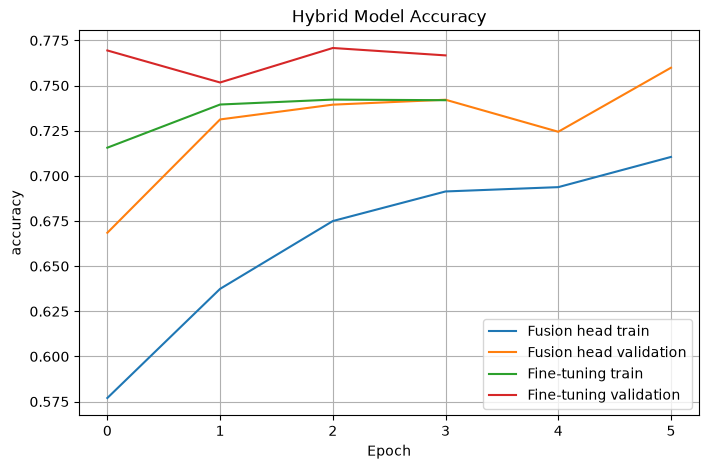

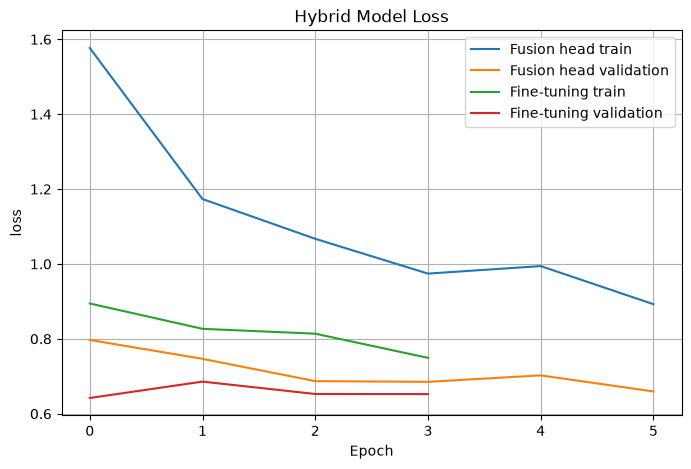

In [10]:
def plot_history(histories, metric, title):
    plt.figure(figsize=(8, 5))
    for label, h in histories:
        if metric in h.history:
            plt.plot(h.history[metric], label=f"{label} train")
        if "val_"+metric in h.history:
            plt.plot(h.history["val_"+metric], label=f"{label} validation")
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel(metric)
    plt.grid(True); plt.legend(); plt.show()

plot_history([("Fusion head", history_head), ("Fine-tuning", history_fine)],
             "accuracy", "Hybrid Model Accuracy")
plot_history([("Fusion head", history_head), ("Fine-tuning", history_fine)],
             "loss", "Hybrid Model Loss")

## 11. Load best model and predict validation set

In [11]:
model = tf.keras.models.load_model(FINAL_MODEL_PATH)
y_true = val_df.diagnosis.to_numpy(dtype=int)
y_prob = model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)
assert len(y_true) == len(y_pred) == len(y_prob)
print("Validation samples:", len(y_true), "| Probability shape:", y_prob.shape)

92/92 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step
Validation samples: 733 | Probability shape: (733, 5)


## 12. Calculate metrics

In [12]:
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
metrics = {
    "accuracy": float(accuracy),
    "macro_precision": float(precision_macro),
    "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro),
    "quadratic_weighted_kappa": float(qwk),
    "validation_images": int(len(y_true)),
    "validation_split_source": "Notebook 05 saved split",
    "architecture": "EfficientNetB3 + MobileNetV2 feature fusion"
}
print(json.dumps(metrics, indent=4))
with open(RESULT_DIR / "hybrid_validation_results.json", "w") as f:
    json.dump(metrics, f, indent=4)

{
    "accuracy": 0.7694406548431105,
    "macro_precision": 0.6164361415182273,
    "macro_recall": 0.6516263088038289,
    "macro_f1": 0.6252764286229788,
    "quadratic_weighted_kappa": 0.8422587779317895,
    "validation_images": 733,
    "validation_split_source": "Notebook 05 saved split",
    "architecture": "EfficientNetB3 + MobileNetV2 feature fusion"
}


## 13. Classification report

In [13]:
report = classification_report(y_true, y_pred, labels=[0,1,2,3,4],
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))
report_df.to_csv(RESULT_DIR / "hybrid_classification_report.csv")

,precision,recall,f1-score,support
0,0.9744,0.9474,0.9607,361.0000
1,0.4312,0.6351,0.5137,74.0000
2,0.7750,0.6200,0.6889,200.0000
3,0.3929,0.5641,0.4632,39.0000
4,0.5088,0.4915,0.5000,59.0000
accuracy,0.7694,0.7694,0.7694,0.7694
macro avg,0.6164,0.6516,0.6253,733.0000
weighted avg,0.7967,0.7694,0.7778,733.0000


## 14. Confusion matrix

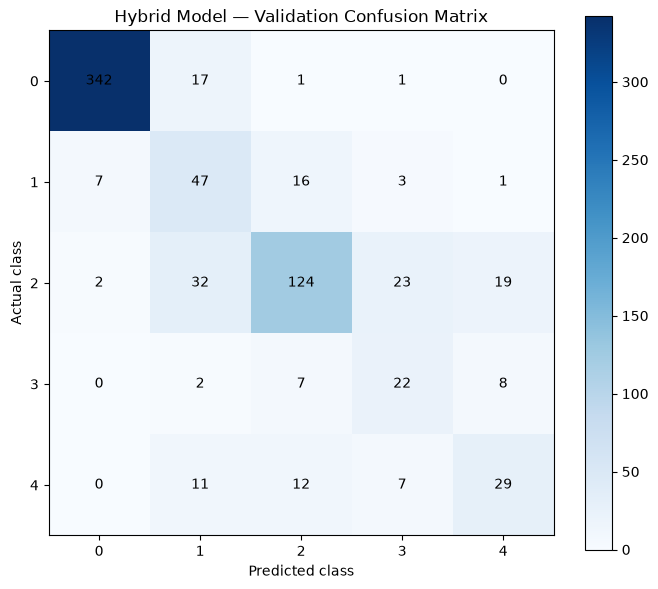

In [14]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Hybrid Model — Validation Confusion Matrix")
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center")
fig.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(RESULT_DIR / "hybrid_confusion_matrix.png", dpi=200)
plt.show()

## 15. Save predictions and incorrect predictions

In [15]:
pred_df = val_df[["id_code", "diagnosis"]].copy()
pred_df.rename(columns={"diagnosis":"actual"}, inplace=True)
pred_df["predicted"] = y_pred
pred_df["confidence"] = confidence
for c in range(NUM_CLASSES):
    pred_df[f"prob_class_{c}"] = y_prob[:,c]
pred_df.to_csv(RESULT_DIR / "hybrid_predictions.csv", index=False)

error_df = pred_df[pred_df.actual != pred_df.predicted].copy()
error_df = error_df.sort_values("confidence", ascending=False)
error_df.to_csv(RESULT_DIR / "hybrid_errors.csv", index=False)
display(error_df.head(20))
print("Incorrect:", len(error_df), "of", len(pred_df))

,id_code,actual,predicted,confidence,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4
495,ae5d31979f19,0,1,0.992921,0.001941,0.992921,0.003458,0.000105,0.001575
562,f066db7a2efe,0,1,0.988516,0.003185,0.988516,0.006382,0.000390,0.001526
600,3f44d749cd0b,0,1,0.983323,0.001098,0.983323,0.011647,0.000627,0.003306
278,253e96488cfb,0,1,0.979254,0.000889,0.979254,0.017278,0.001102,0.001477
630,cb02bb47fdc5,0,1,0.972477,0.003861,0.972477,0.015960,0.002950,0.004752
254,da6389d129aa,0,1,0.970677,0.002837,0.970677,0.022633,0.000793,0.003059
447,a8b637abd96b,0,1,0.948701,0.010110,0.948701,0.021382,0.002263,0.017544
176,262ad704319c,4,3,0.947559,0.000009,0.002444,0.032311,0.947559,0.017677
462,eaa0dfbd5024,4,1,0.939463,0.000805,0.939463,0.046720,0.004410,0.008603
110,5b804948e35f,1,0,0.938677,0.938677,0.027396,0.022365,0.008330,0.003233


Incorrect: 169 of 733


## 16. Display some incorrect predictions

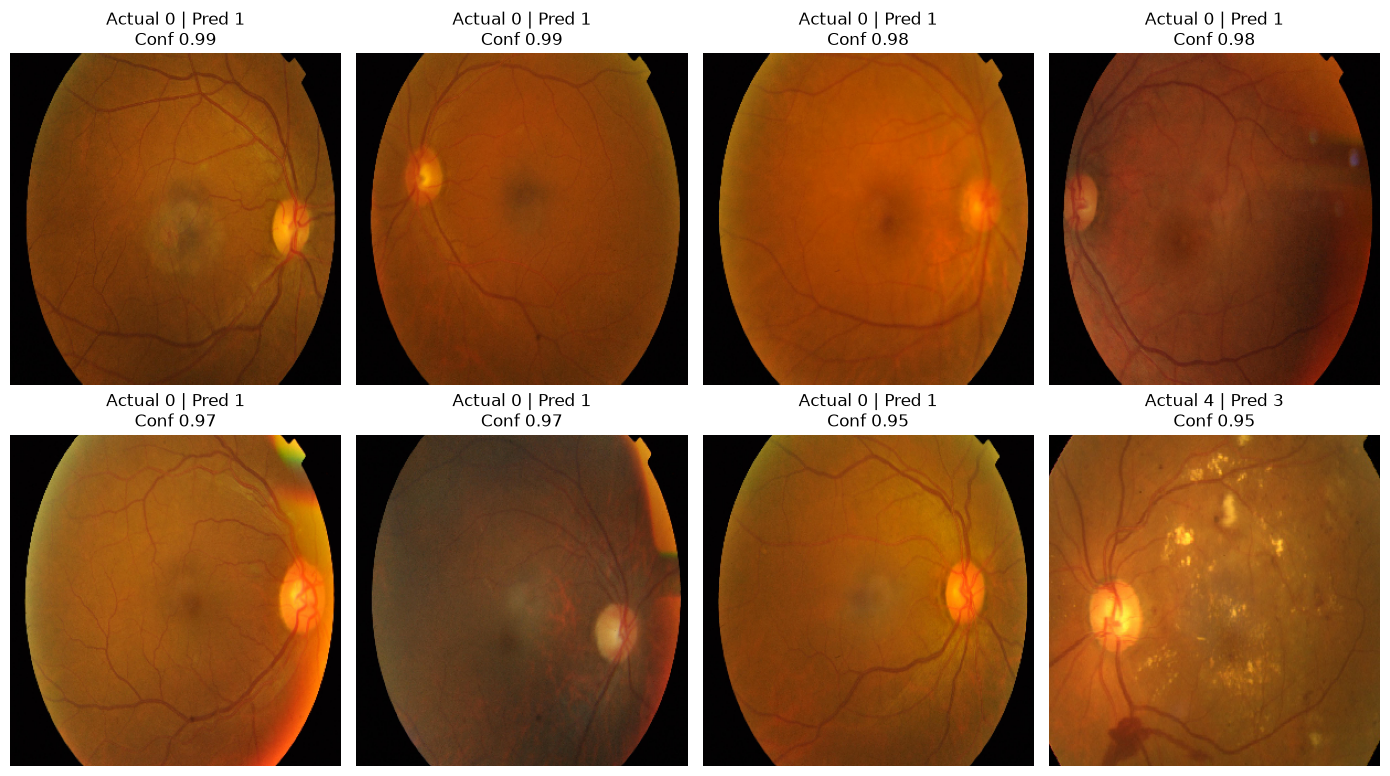

In [16]:
if error_df.empty:
    print("No incorrect validation predictions.")
else:
    plt.figure(figsize=(14,8))
    for i, (_, row) in enumerate(error_df.head(8).iterrows(), 1):
        img = tf.keras.utils.load_img(
            IMAGE_DIR / f"{row.id_code}.png", target_size=(IMG_SIZE, IMG_SIZE))
        plt.subplot(2,4,i); plt.imshow(img)
        plt.title(f"Actual {row.actual} | Pred {row.predicted}\nConf {row.confidence:.2f}")
        plt.axis("off")
    plt.tight_layout(); plt.show()

## 17. Model size and inference latency

In [17]:
model_size_mb = FINAL_MODEL_PATH.stat().st_size / (1024**2)
sample = next(iter(val_ds))[0][:1]
_ = model.predict(sample, verbose=0)
timings = []
for _ in range(10):
    start = time.perf_counter()
    _ = model.predict(sample, verbose=0)
    timings.append(time.perf_counter() - start)
latency_ms = float(np.mean(timings) * 1000)
efficiency = {"model_size_mb": float(model_size_mb),
              "mean_single_image_inference_ms": latency_ms,
              "repeats": 10,
              "note": "Hardware- and system-load-dependent measurement."}
print(json.dumps(efficiency, indent=4))
with open(RESULT_DIR / "hybrid_efficiency.json", "w") as f:
    json.dump(efficiency, f, indent=4)

{
    "model_size_mb": 120.99686813354492,
    "mean_single_image_inference_ms": 420.58542000086163,
    "repeats": 10,
    "note": "Hardware- and system-load-dependent measurement."
}


## 18. Compare EfficientNetB3, MobileNetV2 and Hybrid

In [21]:
metric_files = {
    "EfficientNetB3": RESULT_DIR / "efficientnetb3_validation_results.json",
    "MobileNetV2": RESULT_DIR / "mobilenetv2_validation_results.json",
    "Hybrid": RESULT_DIR / "hybrid_validation_results.json"
}
rows = []
for name, path in metric_files.items():
    if path.exists():
        with open(path, "r") as f:
            m = json.load(f)
        rows.append({
            "Model": name, "Accuracy": m.get("accuracy"),
            "Macro Precision": m.get("macro_precision"),
            "Macro Recall": m.get("macro_recall"),
            "Macro F1": m.get("macro_f1"),
            "QWK": m.get("quadratic_weighted_kappa")
        })
    else:
        print("Metrics file not found:", path.name)
comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))
comparison_df.to_csv(RESULT_DIR / "three_model_metric_comparison.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,QWK
0,EfficientNetB3,0.7408,0.5980,0.6032,0.5735,0.8370
1,MobileNetV2,0.6658,0.4991,0.5396,0.4925,0.7699
2,Hybrid,0.7694,0.6164,0.6516,0.6253,0.8423


## 19. Final summary and saved artifacts

In [19]:
print("HYBRID MODEL VALIDATION SUMMARY")
print("-" * 42)
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro precision: {precision_macro:.4f}")
print(f"Macro recall: {recall_macro:.4f}")
print(f"Macro F1: {f1_macro:.4f}")
print(f"QWK: {qwk:.4f}")
print(f"Model size: {model_size_mb:.2f} MB")
print(f"Inference latency: {latency_ms:.2f} ms/image")
print("\nModel:", FINAL_MODEL_PATH)
print("\nHybrid files:")
for p in sorted(RESULT_DIR.glob("hybrid_*")):
    print(p.name)
print("\nComparison:", RESULT_DIR / "three_model_metric_comparison.csv")

HYBRID MODEL VALIDATION SUMMARY
------------------------------------------
Accuracy: 0.7694 (76.94%)
Macro precision: 0.6164
Macro recall: 0.6516
Macro F1: 0.6253
QWK: 0.8423
Model size: 121.00 MB
Inference latency: 420.59 ms/image

Model: S:\ISP\data\processed\models\hybrid_efficientnetb3_mobilenetv2_final.keras

Hybrid files:
hybrid_classification_report.csv
hybrid_confusion_matrix.png
hybrid_efficiency.json
hybrid_errors.csv
hybrid_finetuning_history.csv
hybrid_predictions.csv
hybrid_stage1_history.csv
hybrid_validation_results.json

Comparison: S:\ISP\data\processed\results\three_model_metric_comparison.csv


In [20]:
import json

efficientnet_metrics = {
    "accuracy": 0.7408,
    "macro_precision": 0.5980,
    "macro_recall": 0.6032,
    "macro_f1": 0.5735,
    "quadratic_weighted_kappa": 0.8370
}

with open(RESULT_DIR / "efficientnetb3_validation_results.json", "w") as f:
    json.dump(efficientnet_metrics, f, indent=4)

print("EfficientNetB3 metrics file created!")

EfficientNetB3 metrics file created!


## Notes and responsible interpretation

- 85% validation accuracy is a target, not a guaranteed outcome.
- If this hybrid misses the target, inspect per-class recall, the confusion matrix and error examples before changing anything.
- Do not change the validation IDs or report an unachieved score.
- Potential follow-up experiments: learning-rate adjustment, unfreezing a different backbone proportion, controlled augmentation changes, and repeated stratified evaluation. Record every run.
- The public APTOS test labels are not provided; these are validation results, not independent test-set metrics.